In [ ]:
# 3C. Implement Anomaly Detection in Energy Consumption Data (Smart Grid
# Dataset) using Autoencoder and build the model by using the following steps:
# Steps:
# • Preprocess the data to fill any missing values, normalize, and create time windows for
# sequential input.
# • Use an LSTM-based autoencoder to learn temporal patterns in normal consumption.
# • Set an error threshold and detect anomalies when the reconstruction error exceeds this
# threshold.
# Dataset: The Smart Grid dataset records electricity consumption across multiple timestamps
# for various households.
# Goal: Detect unusual consumption patterns by training an autoencoder on typical (normal)
# energy usage patterns

In [1]:
# What is an LSTM?
# LSTM stands for Long Short-Term Memory. It is a type of neural network layer built for sequences: data where order matters, like time series, text or audio. A normal neural network treats each input independently. If you feed it hourly energy readings, it has no memory of the previous hours. A basic RNN (recurrent neural network) adds memory by passing a hidden state from one step to the next. But RNNs forget quickly: in long sequences, information from early steps fades away (the vanishing gradient problem). LSTM was designed to remember useful information over long stretches.



import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report

In [2]:
data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/AutoEncoder/Energy Consumption/energy consumption.csv")
print(data)

             Timestamp  Electricity_Consumed  Temperature  Humidity  \
0     01-01-2024 00:00              0.457786     0.469524  0.396368   
1     01-01-2024 00:30              0.351956     0.465545  0.451184   
2     01-01-2024 01:00              0.482948     0.285415  0.408289   
3     01-01-2024 01:30              0.628838     0.482095  0.512308   
4     01-01-2024 02:00              0.335974     0.624741  0.672021   
...                ...                   ...          ...       ...   
4995  14-04-2024 01:30              0.366839     0.701004  0.362397   
4996  14-04-2024 02:00              0.493568     0.258212  0.677895   
4997  14-04-2024 02:30              0.893818     0.431739  0.688926   
4998  14-04-2024 03:00              0.509673     0.592927  0.366151   
4999  14-04-2024 03:30              0.233656     0.612872  0.473481   

      Wind_Speed  Avg_Past_Consumption  Anomaly_Label  
0       0.445441              0.692057              0  
1       0.458729              0.539

In [3]:
# Preprocess : parse timestamps, sort in time order and fill missing values

# ffill (forward fill) : Fills each NaN with the last valid value before it.

# bfill (backward fill) : Fills each NaN with the next valid value after it.

# interpolate : Estimates missing values from the surrounding values. The default is linear, so it draws a straight line between the known points.

data["Timestamp"] = pd.to_datetime(data["Timestamp"] , format="%d-%m-%Y %H:%M")
data = data.sort_values("Timestamp").set_index("Timestamp")

print(data.isnull().sum())

features = ["Electricity_Consumed" , "Temperature" , "Humidity" , "Wind_Speed" , "Avg_Past_Consumption"]
data[features] = data[features].interpolate(method="time").bfill().ffill()

Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


In [27]:
X = data[features].values
y = data["Anomaly_Label"].values

In [28]:
# Time-ordered split (no shuffling for time series) : first 80% train , last 20% test
split = int(len(X) * 0.8)
x_train , x_test = X[:split] , X[split:]
y_train , y_test = y[:split] , y[split:]

In [29]:
# Normalize : fit the scaler on training data only
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [31]:
# No time windows : each reading is treated as a sequence of 1 timestep
x_train = x_train.reshape(-1 , 1 , x_train.shape[1])
x_test = x_test.reshape(-1 , 1 , x_test.shape[1])

# Train only on normal readings
x_train = x_train[y_train == 0]

print(x_train.shape , x_test.shape)

(3805, 1, 5) (1000, 1, 5)


In [ ]:
# Encoder : LSTM(32, return_sequences=True) reads the input and outputs a vector of 32 values for every timestep, so the shape is (batch, timesteps, 32). LSTM(8) reads that sequence and outputs only the final state, an 8-number summary of the whole sequence, with shape (batch, 8) RepeatVector(timesteps) copies that 8-number vector timesteps times, giving (batch, timesteps, 8).

#Decoder : LSTM(8, return_sequences=True) and LSTM(32, return_sequences=True) expand back up, giving an output at every timestep. TimeDistributed(Dense(n_features)) applies the same Dense layer to each timestep and maps 32 values back to 5. The output is (batch, timesteps, 5), the same shape as the input.



class Autoencoder(keras.Model):
    def __init__(self , timesteps , n_features):
        super().__init__()

        self.encoder = keras.Sequential([
            keras.layers.LSTM(32 , return_sequences = True),
            keras.layers.LSTM(8),
            keras.layers.RepeatVector(timesteps),
        ])

        self.decoder = keras.Sequential([
            keras.layers.LSTM(8 , return_sequences = True),
            keras.layers.LSTM(32 , return_sequences = True),
            keras.layers.TimeDistributed(keras.layers.Dense(n_features)),
        ])

    def call(self , inputs):
        return self.decoder(self.encoder(inputs))

model = Autoencoder(x_train.shape[1] , x_train.shape[2])

In [33]:
model.compile(optimizer="adam" , loss="mse")

In [34]:
history = model.fit(x_train , x_train , epochs=30 , batch_size=64 , validation_split=0.1 , shuffle=False)

Epoch 1/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.1842 - val_loss: 0.1124
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0441 - val_loss: 0.0173
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0174 - val_loss: 0.0171
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0171 - val_loss: 0.0168
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0169 - val_loss: 0.0164
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0165 - val_loss: 0.0161
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0162 - val_loss: 0.0157
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0159 - val_loss: 0.0154
Epoch 9/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0156 - val_loss: 0.0151
Epoch 10/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0154 - val_loss: 0.0150
Epoch 11/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0153 - val_loss: 0.0149
Epoch 12/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0153 - val_lo

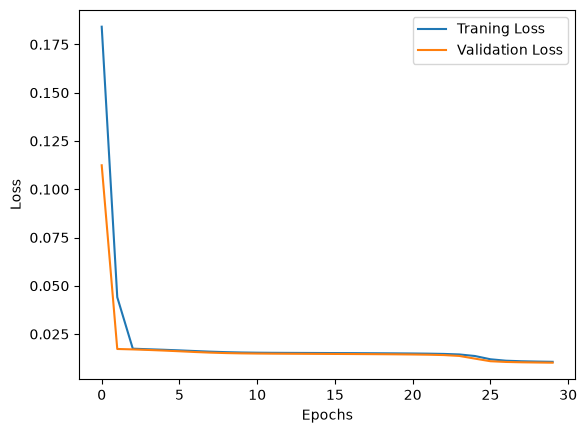

In [35]:
plt.plot(history.history["loss"] , label = "Traning Loss")
plt.plot(history.history["val_loss"] , label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [42]:
def get_errors(original , reconstructed):
    # error of the latest reading in each window (averaged over the features)
    return np.mean(
        (original - reconstructed) ** 2 , axis = 2
    )

In [43]:
train_errors = get_errors(x_train , model.predict(x_train , verbose=0))

In [44]:
threshold = np.percentile(train_errors , 95)
print(threshold)

0.026828351233404768


In [45]:
test_errors = get_errors(x_test , model.predict(x_test , verbose = 0))
predictions = np.where(test_errors > threshold , 1 ,0)

In [46]:
print(classification_report(y_test , predictions , target_names=["Normal" , "Anomaly"]))

              precision    recall  f1-score   support

      Normal       0.95      0.96      0.95       945
     Anomaly       0.16      0.15      0.15        55

    accuracy                           0.91      1000
   macro avg       0.56      0.55      0.55      1000
weighted avg       0.91      0.91      0.91      1000



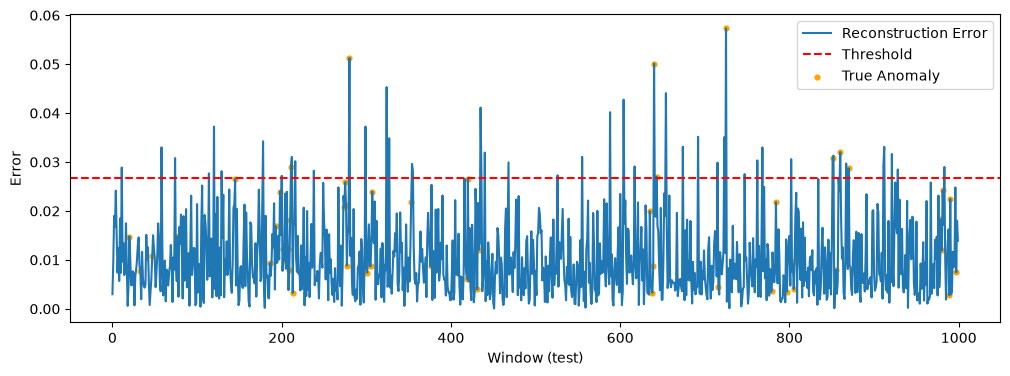

In [47]:
plt.figure(figsize=(12 , 4))
plt.plot(test_errors , label = "Reconstruction Error")
plt.axhline(threshold , color = "r" , linestyle = "--" , label = "Threshold")
plt.scatter(np.where(y_test == 1)[0] , test_errors[y_test == 1] , color = "orange" , s = 12 , label = "True Anomaly")
plt.xlabel("Window (test)")
plt.ylabel("Error")
plt.legend()